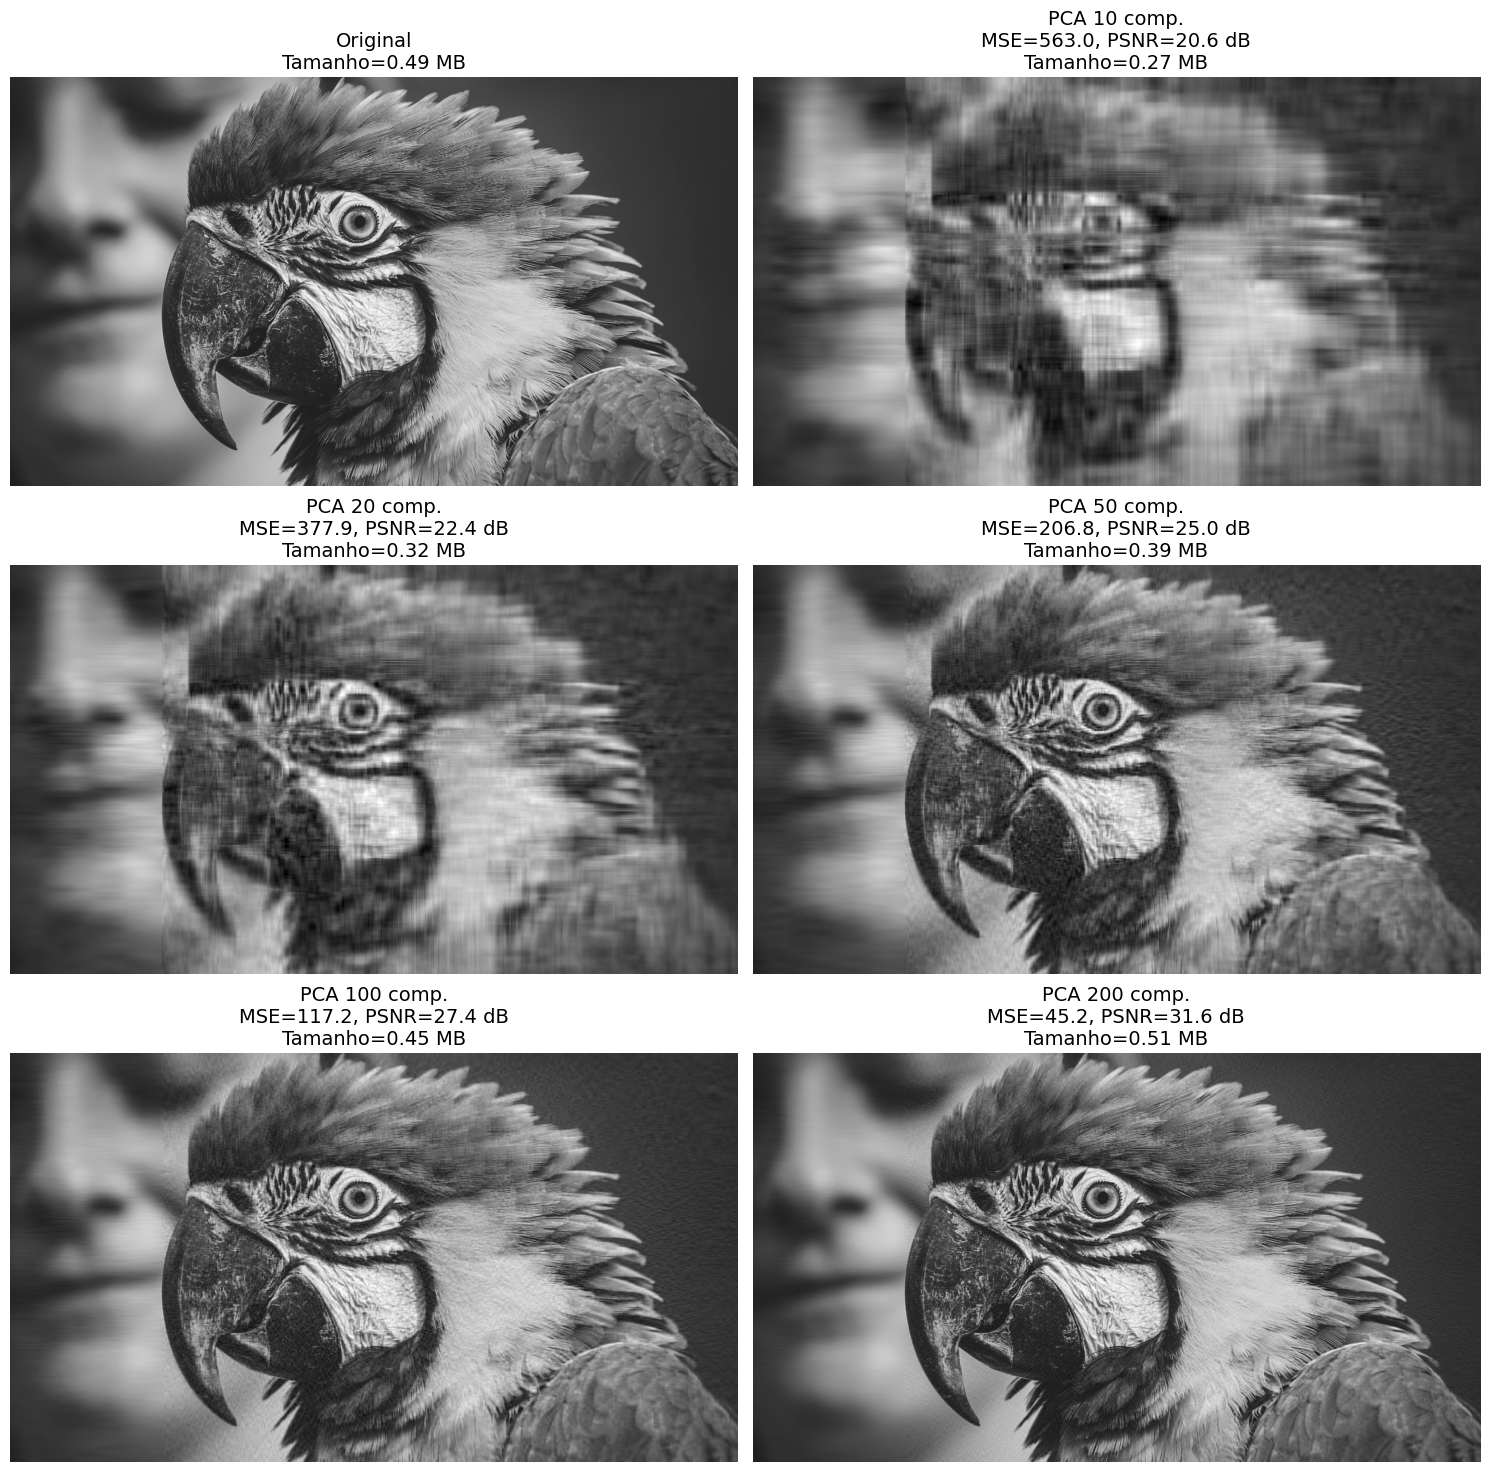

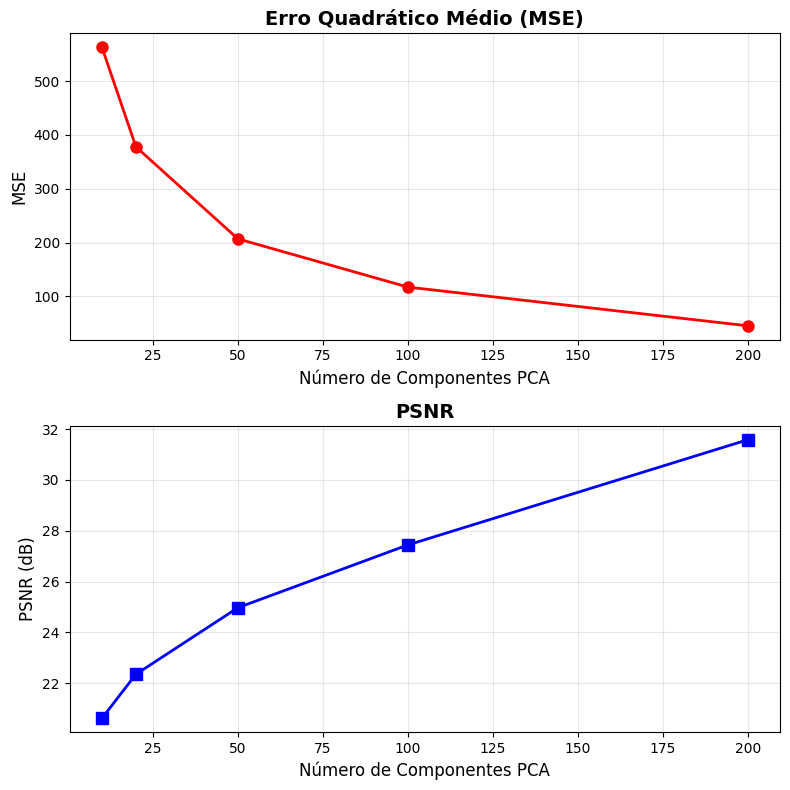

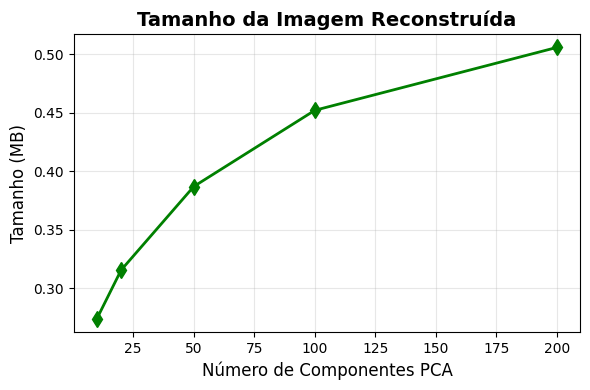

In [2]:
import numpy as np
from PIL import Image
from sklearn.decomposition import PCA
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio
import matplotlib.pyplot as plt
import io
from pathlib import Path

output_dir = "../images/output_pca"

Path(output_dir).mkdir(exist_ok=True, parents=True)


# Função para obter tamanho em MB
def tamanho_em_mb(pil_img, formato="PNG"):
    buffer = io.BytesIO()
    pil_img.save(buffer, format=formato)
    return buffer.tell() / 1024**2


# números de componentes para reconstrução
componentes_list = [
    10,
    20,
    50,
    100,
    200,
]

# Disponnível em "https://pixabay.com/pt/photos/papagaio-arara-azul-e-amarela-3695678/"
caminho = "../images/parrot-3695678_1280.jpg"

# Carregar imagem escala de cinza
img = Image.open(caminho).convert("L")
img_array = np.array(img)
altura, largura = img_array.shape


# Tamanho da imagem original
tamanho_original = tamanho_em_mb(img)

# Listas para armazenar métricas
mse_list = []
psnr_list = []
tamanho_list = []
recon_images = []

# Reconstruir imagens com PCA e calcular métricas
for n_comp in componentes_list:
    pca = PCA(n_components=n_comp)
    img_transformed = pca.fit_transform(img_array)
    img_recon = pca.inverse_transform(img_transformed)
    img_recon = np.clip(img_recon, 0, 255).astype(np.uint8)

    recon_images.append(img_recon)
    mse_list.append(mean_squared_error(img_array, img_recon))
    psnr_list.append(peak_signal_noise_ratio(img_array, img_recon))
    tamanho_list.append(tamanho_em_mb(Image.fromarray(img_recon)))

# Plot das imagens (grid 3x2)
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()
fig.patch.set_facecolor("white")

# Primeira imagem é a original
axes[0].imshow(img_array, cmap="gray")
axes[0].axis("off")
axes[0].set_title(f"Original\nTamanho={tamanho_original:.2f} MB", fontsize=14)

# Reconstruções PCA
for idx, (img_recon, n_comp, mse, psnr, tamanho_recon) in enumerate(
    zip(recon_images, componentes_list, mse_list, psnr_list, tamanho_list)
):
    axes[idx + 1].imshow(img_recon, cmap="gray")
    axes[idx + 1].axis("off")
    axes[idx + 1].set_title(
        f"PCA {n_comp} comp.\nMSE={mse:.1f}, PSNR={psnr:.1f} dB\nTamanho={tamanho_recon:.2f} MB",
        fontsize=14,
    )

plt.tight_layout()
plt.savefig(Path(output_dir, "grid_pca_images.png"), dpi=300)
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(8, 8))

# MSE vs Número de Componentes
axes[0].plot(componentes_list, mse_list, "o-", color="red", linewidth=2, markersize=8)
axes[0].set_xlabel("Número de Componentes PCA", fontsize=12)
axes[0].set_ylabel("MSE", fontsize=12)
axes[0].set_title("Erro Quadrático Médio (MSE)", fontsize=14, fontweight="bold")
axes[0].grid(True, alpha=0.3)

# PSNR vs Número de Componentes
axes[1].plot(componentes_list, psnr_list, "s-", color="blue", linewidth=2, markersize=8)
axes[1].set_xlabel("Número de Componentes PCA", fontsize=12)
axes[1].set_ylabel("PSNR (dB)", fontsize=12)
axes[1].set_title("PSNR", fontsize=14, fontweight="bold")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(Path(output_dir, "mse_psnr_vs_components.png"), dpi=300)
plt.show()

# Plot separado: Tamanho
plt.figure(figsize=(6, 4))
plt.plot(componentes_list, tamanho_list, "d-", color="green", linewidth=2, markersize=8)
plt.xlabel("Número de Componentes PCA", fontsize=12)
plt.ylabel("Tamanho (MB)", fontsize=12)
plt.title("Tamanho da Imagem Reconstruída", fontsize=14, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(Path(output_dir, "size_vs_components.png"), dpi=300)
plt.show()